# POC-ABS Real Data — Eye ROI vs Apex Frame

Notebook ini versi real-data dari `comparasion/notebooks/test_poc_abs_blocks_modified_v2.ipynb`.

Alur:
1. ambil event dari `output/apex/datatest/metadata.xlsx` / hasil `process_all_datasets.ipynb`;
2. pakai frame pertama event sebagai referensi;
3. pakai frame apex (`*-apex.png`) sebagai citra target;
4. ekstrak ROI mata (`mata_kiri` / `mata_kanan`);
5. hitung + visualisasi POC-ABS.

In [79]:
import json
import os
import re
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent.parent
elif ROOT.name == "comparasion":
    ROOT = ROOT.parent
elif ROOT.name in {"lstm", "svm", "knn"}:
    ROOT = ROOT.parent.parent.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(f"Project root: {ROOT}")

Project root: /home/ryuko/Documents/Codes/Python/Skripsi/Convat-1st


In [80]:
import cv2
import dlib
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.special import expit
from sklearn.metrics import classification_report, confusion_matrix, log_loss, roc_auc_score
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

from comparasion.core.config import ComparisonConfig
from comparasion.core.roi import ROIExtractor
from features_extraction.poc import POC

## 1. Konfigurasi real data

In [81]:
OUTPUT_ROOT = ROOT / 'output' / 'apex' / 'datatest'
METADATA_PATH = OUTPUT_ROOT / 'metadata.xlsx'

ROI_NAME = 'mulut'  # opsi: mulut, mata_kiri, mata_kanan
BLOCK_SIZE = 7
SHOW_POC_DEBUG = False

# Custom pilih event. Isi salah satu / beberapa filter ini, atau biarkan None untuk auto-pick event pertama yang readable.
SELECT_EVENT_INDEX = None  # contoh: 0, 1, 2 ... indeks baris metadata setelah filter
SELECT_RELATIVE_SAMPLE_CONTAINS = "anxiety_rendah/"  # contoh: 'q4/Abelas Solihin_4'
SELECT_EVENT_NO = 1  # contoh: 1
SELECT_APEX_FRAME = None  # contoh: 13

TABR_ROOT = ROOT / 'third_party' / 'tabular-dl-tabr-official'
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
TABR_DATASET_NAME = 'convat_apex_anxiety_qwalk_q123_q4_q5'
TABR_RUN_DIR = TABR_ROOT / 'exp' / 'tabr' / TABR_DATASET_NAME / '0-evaluation' / '0'
TABR_DATA_DIR = TABR_ROOT / 'data' / TABR_DATASET_NAME
ARTIFACT_DIR = ROOT / 'output' / 'apex' / 'tabr_question_timeaware_artifacts' / TABR_DATASET_NAME

config = ComparisonConfig(
    predictor_path=ROOT / 'preprocess-anxiety' / 'models' / 'shape_predictor_68_face_landmarks.dat',
    output_root=OUTPUT_ROOT,
    regions={
        'mulut': list(range(48, 68)),
    },
    target_size={
        'mulut': (70, 35),
    },
    padding_x=6,
    padding_y=8,
    block_size=BLOCK_SIZE,
)

extractor = ROIExtractor(config)
metadata = pd.read_excel(METADATA_PATH)
metadata[metadata['relative_sample'].astype(str).str.contains(SELECT_RELATIVE_SAMPLE_CONTAINS or '', case=False, regex=False)].head()

,relative_sample,source_video,event_no,onset_signal,apex_signal,offset_signal,onset_frame,apex_frame,offset_frame,duration,saved_frames,window_length,polyorder,height_threshold,clip_dir
0,15_04_2026/anxiety_rendah/abelas_solihin_17762...,/home/ryuko/Documents/Codes/Python/Skripsi/Con...,1,8,12,17,9,13,18,9,10,9,3,0.1701,dataset/15_04_2026/anxiety_rendah/abelas_solih...
1,15_04_2026/anxiety_rendah/abelas_solihin_17762...,/home/ryuko/Documents/Codes/Python/Skripsi/Con...,2,18,22,25,19,23,26,7,8,9,3,0.1701,dataset/15_04_2026/anxiety_rendah/abelas_solih...
2,15_04_2026/anxiety_rendah/abelas_solihin_17762...,/home/ryuko/Documents/Codes/Python/Skripsi/Con...,3,31,36,40,32,37,41,9,10,9,3,0.1701,dataset/15_04_2026/anxiety_rendah/abelas_solih...
3,15_04_2026/anxiety_rendah/abelas_solihin_17762...,/home/ryuko/Documents/Codes/Python/Skripsi/Con...,4,53,58,61,54,59,62,8,9,9,3,0.1701,dataset/15_04_2026/anxiety_rendah/abelas_solih...
4,15_04_2026/anxiety_rendah/abelas_solihin_17762...,/home/ryuko/Documents/Codes/Python/Skripsi/Con...,5,68,72,93,69,73,94,25,26,9,3,0.1701,dataset/15_04_2026/anxiety_rendah/abelas_solih...


## 2. Pilih event yang punya frame apex

In [82]:
def natural_sort_key(value: str):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', value)]


def event_dir_from_row(row: pd.Series) -> Path:
    clip_dir = Path(str(row['clip_dir']))
    if clip_dir.is_absolute():
        return clip_dir
    return OUTPUT_ROOT / clip_dir


def list_event_frames(event_dir: Path) -> list[Path]:
    frames = [
        p for p in event_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
    ]
    return sorted(frames, key=lambda p: natural_sort_key(p.name))


def find_apex_frame(event_dir: Path) -> Path | None:
    candidates = sorted(event_dir.glob('*apex*'), key=lambda p: natural_sort_key(p.name))
    return candidates[0] if candidates else None


def filter_metadata(metadata: pd.DataFrame) -> pd.DataFrame:
    df = metadata.copy()
    if SELECT_RELATIVE_SAMPLE_CONTAINS:
        df = df[df['relative_sample'].astype(str).str.contains(SELECT_RELATIVE_SAMPLE_CONTAINS, case=False, regex=False)]
    if SELECT_EVENT_NO is not None:
        df = df[df['event_no'].astype(int) == int(SELECT_EVENT_NO)]
    if SELECT_APEX_FRAME is not None:
        df = df[df['apex_frame'].astype(int) == int(SELECT_APEX_FRAME)]
    return df.reset_index(drop=True)


def row_is_readable(row: pd.Series, roi_name: str) -> tuple[bool, Path | None, Path | None, Path | None]:
    event_dir = event_dir_from_row(row)
    if not event_dir.exists():
        return False, event_dir, None, None
    frames = list_event_frames(event_dir)
    apex_path = find_apex_frame(event_dir)
    if len(frames) < 2 or apex_path is None:
        return False, event_dir, None, apex_path
    ref_path = next((p for p in frames if 'apex' not in p.stem.lower()), frames[0])
    ref_img = cv2.imread(str(ref_path))
    apex_img = cv2.imread(str(apex_path))
    if ref_img is None or apex_img is None:
        return False, event_dir, ref_path, apex_path
    try:
        _ = extractor.extract_rois(ref_img)[roi_name]
        _ = extractor.extract_rois(apex_img)[roi_name]
    except Exception:
        return False, event_dir, ref_path, apex_path
    return True, event_dir, ref_path, apex_path


def find_readable_eye_event(metadata: pd.DataFrame, roi_name: str = ROI_NAME) -> tuple[pd.Series, Path, Path, Path]:
    filtered = filter_metadata(metadata)
    if SELECT_EVENT_INDEX is not None:
        if SELECT_EVENT_INDEX >= len(filtered):
            raise IndexError(f'SELECT_EVENT_INDEX={SELECT_EVENT_INDEX}, filtered rows={len(filtered)}')
        row = filtered.iloc[int(SELECT_EVENT_INDEX)]
        ok, event_dir, ref_path, apex_path = row_is_readable(row, roi_name)
        if not ok:
            raise RuntimeError(f'Selected event tidak readable: {event_dir}')
        return row, event_dir, ref_path, apex_path

    for _, row in filtered.iterrows():
        ok, event_dir, ref_path, apex_path = row_is_readable(row, roi_name)
        if ok:
            return row, event_dir, ref_path, apex_path
    raise RuntimeError(f'Tidak menemukan event readable untuk ROI {roi_name}. Filtered rows={len(filtered)}')


filtered_metadata = filter_metadata(metadata)
display(filtered_metadata[['relative_sample', 'event_no', 'onset_frame', 'apex_frame', 'offset_frame', 'duration']].head(20))

selected_row, event_dir, reference_frame_path, apex_frame_path = find_readable_eye_event(metadata)

print('Event dir       :', event_dir)
print('Reference frame :', reference_frame_path.name)
print('Apex frame      :', apex_frame_path.name)
print('Apex global     :', int(selected_row['apex_frame']))
selected_row[['relative_sample', 'event_no', 'onset_frame', 'apex_frame', 'offset_frame', 'duration']]

,relative_sample,event_no,onset_frame,apex_frame,offset_frame,duration
0,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,9,13,18,9
1,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,13,14,20,7
2,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,7,11,17,10
3,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,35,49,63,28
4,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,7,17,21,14
5,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,14,20,26,12
6,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,51,65,68,17
7,15_04_2026/anxiety_rendah/abelas_solihin_17762...,1,48,52,58,10
8,15_04_2026/anxiety_rendah/alfreda_dhaifullah_m...,1,53,58,64,11
9,15_04_2026/anxiety_rendah/alfreda_dhaifullah_m...,1,8,14,19,11


Event dir       : /home/ryuko/Documents/Codes/Python/Skripsi/Convat-1st/output/apex/datatest/dataset/15_04_2026/anxiety_rendah/abelas_solihin_1776232231169/q4/Abelas Solihin_4_497eb431-dd00-4530-858f-e8ec710014e7_main/event_00009-00018
Reference frame : frame_00000.jpg
Apex frame      : frame_00004-apex.png
Apex global     : 13


relative_sample    15_04_2026/anxiety_rendah/abelas_solihin_17762...
event_no                                                           1
onset_frame                                                        9
apex_frame                                                        13
offset_frame                                                      18
duration                                                           9
Name: 0, dtype: object

## 3. Load citra referensi dan citra target apex

In [83]:
reference_bgr = cv2.imread(str(reference_frame_path))
target_bgr = cv2.imread(str(apex_frame_path))
if reference_bgr is None:
    raise FileNotFoundError(reference_frame_path)
if target_bgr is None:
    raise FileNotFoundError(apex_frame_path)

reference_rois = extractor.extract_rois(reference_bgr)
target_rois = extractor.extract_rois(target_bgr)

reference_roi = cv2.cvtColor(reference_rois[ROI_NAME], cv2.COLOR_BGR2GRAY)
target_roi = cv2.cvtColor(target_rois[ROI_NAME], cv2.COLOR_BGR2GRAY)

print(f'ROI: {ROI_NAME}')
print(f'Reference ROI shape: {reference_roi.shape}')
print(f'Target ROI shape   : {target_roi.shape}')

ROI: mulut
Reference ROI shape: (35, 70)
Target ROI shape   : (35, 70)


## 4. POC-ABS dan fungsi visualisasi

In [84]:
def extract_poc_abs_feature(current_roi: np.ndarray, reference_roi: np.ndarray, block_size: int) -> np.ndarray:
    return POC(current_roi, reference_roi, block_size).getPOC()[0]


def get_actual_poc_peak(poc_abs_map: np.ndarray) -> tuple[tuple[int, int], tuple[int, int], float, int]:
    if poc_abs_map.ndim == 3:
        block_idx = int(np.argmax(poc_abs_map.max(axis=(0, 1))))
        poc_2d = poc_abs_map[:, :, block_idx]
    else:
        block_idx = 0
        poc_2d = poc_abs_map

    peak_y, peak_x = np.unravel_index(np.argmax(poc_2d), poc_2d.shape)
    center_y = poc_2d.shape[0] // 2
    center_x = poc_2d.shape[1] // 2
    return (int(peak_x), int(peak_y)), (int(peak_x - center_x), int(peak_y - center_y)), float(poc_2d[peak_y, peak_x]), block_idx


def difference_score(reference: np.ndarray, target: np.ndarray) -> float:
    diff = np.abs(target.astype(np.int16) - reference.astype(np.int16))
    score = 1.0 - float(diff.sum()) / float(255 * diff.size)
    return max(0.0, min(1.0, score))


def strongest_diff_centers(reference: np.ndarray, target: np.ndarray, q: float = 0.92):
    diff = np.abs(target.astype(np.int16) - reference.astype(np.int16)).astype(np.float32)
    threshold = float(np.quantile(diff, q))
    mask = diff >= max(1.0, threshold)
    if not mask.any():
        h, w = reference.shape
        c = ((w - 1) / 2.0, (h - 1) / 2.0)
        return c, c, mask
    ys, xs = np.where(mask)
    center = (float(xs.mean()), float(ys.mean()))
    h, w = reference.shape
    roi_center = ((w - 1) / 2.0, (h - 1) / 2.0)
    return roi_center, center, mask


def plot_eye_roi_case(reference: np.ndarray, target: np.ndarray, poc_abs_map: np.ndarray, title: str):
    actual_peak, actual_shift, actual_peak_val, block_idx = get_actual_poc_peak(poc_abs_map)
    score = difference_score(reference, target)
    roi_center, diff_center, diff_mask = strongest_diff_centers(reference, target)

    diff_signed = target.astype(np.int16) - reference.astype(np.int16)
    diff_abs = np.abs(diff_signed).astype(np.uint8)

    if SHOW_POC_DEBUG:
        fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
    else:
        fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))

    panels = [
        (reference, 'Citra Referensi\nframe awal event', 'gray'),
        (target, 'Citra Target\nframe apex', 'gray'),
        (diff_abs, f'ABS Difference\nscore={score:.4f}', 'magma'),
    ]

    for ax, (img, ttl, cmap) in zip(axes[:3], panels):
        ax.imshow(img, cmap=cmap)
        ax.set_title(ttl)
        ax.set_xticks([])
        ax.set_yticks([])

    h, w = reference.shape
    for ax in axes[:3]:
        ax.add_patch(Rectangle((0, 0), w - 1, h - 1, fill=False, edgecolor='red', linewidth=1.2))

    sx, sy = roi_center
    ex, ey = diff_center
    if (abs(ex - sx) + abs(ey - sy)) > 0.5:
        axes[2].arrow(
            sx, sy, ex - sx, ey - sy,
            color='cyan', width=0.25, head_width=2.2, head_length=2.8,
            length_includes_head=True,
        )

    if SHOW_POC_DEBUG:
        ax = axes[3]
        ax.imshow(poc_abs_map[:, :, block_idx], cmap='viridis')
        ax.scatter([actual_peak[0]], [actual_peak[1]], c='red', s=80, marker='x')
        ax.set_title(
            f'POC debug block #{block_idx + 1}\n'
            f'shift={actual_shift}, peak={actual_peak_val:.4f}'
        )
        ax.set_xticks(range(BLOCK_SIZE))
        ax.set_yticks(range(BLOCK_SIZE))
        ax.grid(color='white', alpha=0.35)

    fig.suptitle(title, fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

    return {
        'display_score': score,
        'display_shift': (ex - sx, ey - sy),
        'diff_center': diff_center,
        'actual_poc_peak': actual_peak,
        'actual_poc_shift': actual_shift,
        'actual_poc_peak_val': actual_peak_val,
        'actual_poc_block': block_idx + 1,
    }

## 5. Case — Eye ROI reference vs apex target

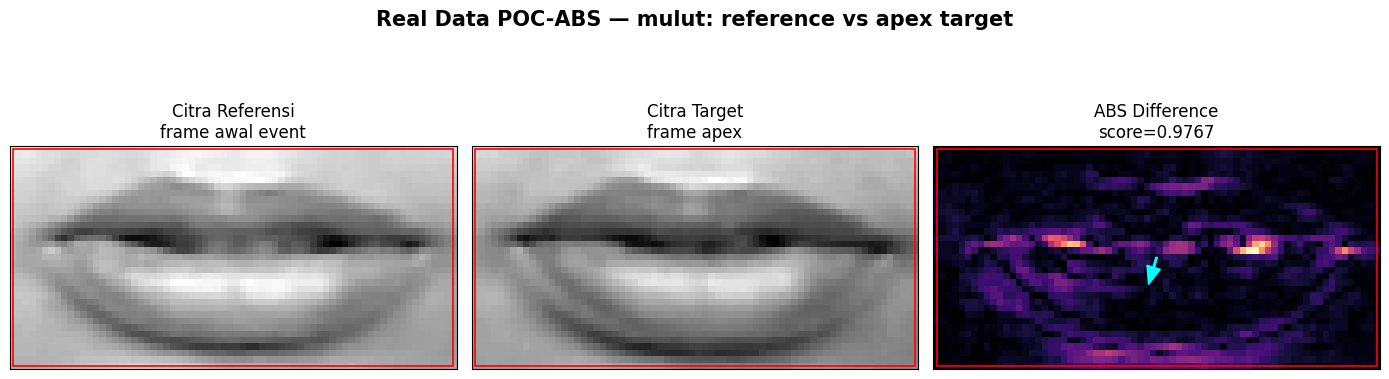

Real Data Case
ROI                  : mulut
Reference frame      : frame_00000.jpg
Apex target frame    : frame_00004-apex.png
Display score        : 0.976687
Display shift        : (-1.2681159420289845, 4.246376811594203)
Actual POC block     : 38
Actual POC peak      : 0.978689
Actual POC shift     : (0, 0)


In [85]:
poc_real_eye = extract_poc_abs_feature(
    current_roi=target_roi,
    reference_roi=reference_roi,
    block_size=BLOCK_SIZE,
)

case_real = plot_eye_roi_case(
    reference_roi,
    target_roi,
    poc_real_eye,
    title=f'Real Data POC-ABS — {ROI_NAME}: reference vs apex target',
)

print('Real Data Case')
print(f"ROI                  : {ROI_NAME}")
print(f"Reference frame      : {reference_frame_path.name}")
print(f"Apex target frame    : {apex_frame_path.name}")
print(f"Display score        : {case_real['display_score']:.6f}")
print(f"Display shift        : {case_real['display_shift']}")
print(f"Actual POC block     : {case_real['actual_poc_block']}")
print(f"Actual POC peak      : {case_real['actual_poc_peak_val']:.6f}")
print(f"Actual POC shift     : {case_real['actual_poc_shift']}")

## 6. Confusion matrix + kurva TabR

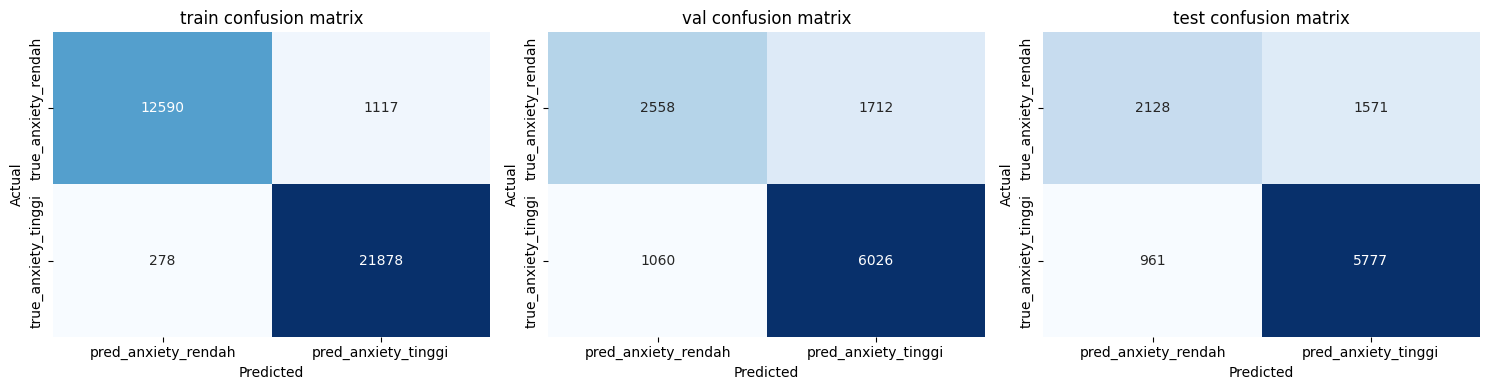

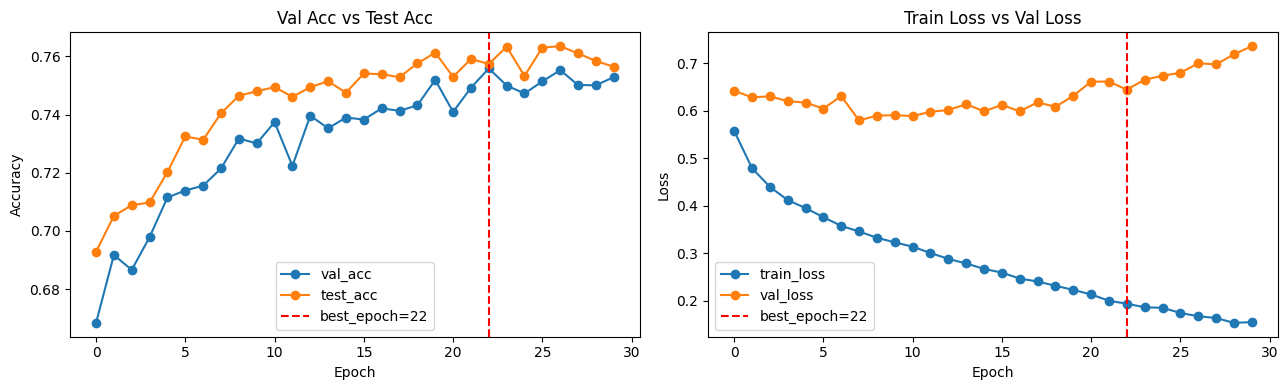

Saved to: /home/ryuko/Documents/Codes/Python/Skripsi/Convat-1st/output/apex/tabr_question_timeaware_artifacts/convat_apex_anxiety_qwalk_q123_q4_q5
Best epoch: 22


,pred_anxiety_rendah,pred_anxiety_tinggi
true_anxiety_rendah,2128,1571
true_anxiety_tinggi,961,5777


,precision,recall,f1-score,support
0,0.688896,0.575291,0.626989,3699.000000
1,0.786200,0.857376,0.820247,6738.000000
accuracy,0.757402,0.757402,0.757402,0.757402
macro avg,0.737548,0.716333,0.723618,10437.000000
weighted avg,0.751715,0.757402,0.751754,10437.000000
cross-entropy,0.621328,0.621328,0.621328,0.621328
roc-auc,0.817290,0.817290,0.817290,0.817290
score,0.757402,0.757402,0.757402,0.757402


In [86]:
def load_tabr_predictions(run_dir: Path) -> dict[str, np.ndarray]:
    pred_path = run_dir / 'predictions.npz'
    if not pred_path.exists():
        raise FileNotFoundError(pred_path)
    data = np.load(pred_path)
    return {k: data[k] for k in data.files}


def make_confusion_df(y_true: np.ndarray, logits: np.ndarray, threshold: float = 0.5) -> pd.DataFrame:
    prob = expit(logits)
    pred = (prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    return pd.DataFrame(
        cm,
        index=['true_anxiety_rendah', 'true_anxiety_tinggi'],
        columns=['pred_anxiety_rendah', 'pred_anxiety_tinggi'],
    )


def make_score_df(y_true: np.ndarray, logits: np.ndarray, threshold: float = 0.5) -> pd.DataFrame:
    prob = expit(logits)
    pred = (prob >= threshold).astype(int)
    report = classification_report(y_true, pred, labels=[0, 1], output_dict=True, zero_division=0)
    score_df = pd.DataFrame(report).T
    ce = float(log_loss(y_true, prob, labels=[0, 1]))
    auc = float(roc_auc_score(y_true, prob))
    acc = float((pred == y_true).mean())
    for name, value in [('cross-entropy', ce), ('roc-auc', auc), ('score', acc)]:
        score_df.loc[name, ['precision', 'recall', 'f1-score', 'support']] = value
    return score_df


def load_epoch_metrics(run_dir: Path) -> tuple[pd.DataFrame, int]:
    import lib

    checkpoint = lib.load_checkpoint(run_dir, map_location='cpu')
    rows = []
    for epoch, item in enumerate(checkpoint['training_log']):
        metrics = item['metrics']
        epoch_losses = item.get('epoch-losses', [])
        rows.append({
            'epoch': epoch,
            'train_loss': float(np.mean(epoch_losses)) if len(epoch_losses) else np.nan,
            'val_loss': float(metrics['val'].get('cross-entropy', np.nan)),
            'test_loss': float(metrics['test'].get('cross-entropy', np.nan)),
            'val_acc': float(metrics['val']['score']),
            'test_acc': float(metrics['test']['score']),
        })
    report = json.loads((run_dir / 'report.json').read_text())
    return pd.DataFrame(rows), int(report['best_epoch'])


def save_tabr_confusions_and_plots(run_dir: Path, data_dir: Path, artifact_dir: Path) -> dict:
    import sys
    os.environ['PROJECT_DIR'] = str(TABR_ROOT)
    if str(TABR_ROOT) not in sys.path:
        sys.path.append(str(TABR_ROOT))

    artifact_dir.mkdir(parents=True, exist_ok=True)
    preds = load_tabr_predictions(run_dir)
    y = {part: np.load(data_dir / f'Y_{part}.npy') for part in ['train', 'val', 'test']}

    cm = {part: make_confusion_df(y[part], preds[part]) for part in ['train', 'val', 'test']}
    scores = {part: make_score_df(y[part], preds[part]) for part in ['train', 'val', 'test']}
    with pd.ExcelWriter(artifact_dir / 'confusion_matrices.xlsx') as writer:
        for part, cm_df in cm.items():
            cm_df.to_excel(writer, sheet_name=part)
        for part, score_df in scores.items():
            score_df.to_excel(writer, sheet_name=f'{part}_scores')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, part in zip(axes, ['train', 'val', 'test']):
        sns.heatmap(cm[part], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
        ax.set_title(f'{part} confusion matrix')
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')
    plt.tight_layout()
    cm_png = artifact_dir / 'confusion_matrices.png'
    fig.savefig(cm_png, dpi=180, bbox_inches='tight')
    plt.show()

    epoch_df, best_epoch = load_epoch_metrics(run_dir)
    epoch_df.to_csv(artifact_dir / 'epoch_metrics.csv', index=False)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epoch_df['epoch'], epoch_df['val_acc'], marker='o', label='val_acc')
    axes[0].plot(epoch_df['epoch'], epoch_df['test_acc'], marker='o', label='test_acc')
    axes[0].axvline(best_epoch, linestyle='--', color='red', label=f'best_epoch={best_epoch}')
    axes[0].set_title('Val Acc vs Test Acc')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    axes[1].plot(epoch_df['epoch'], epoch_df['train_loss'], marker='o', label='train_loss')
    axes[1].plot(epoch_df['epoch'], epoch_df['val_loss'], marker='o', label='val_loss')
    axes[1].axvline(best_epoch, linestyle='--', color='red', label=f'best_epoch={best_epoch}')
    axes[1].set_title('Train Loss vs Val Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    plt.tight_layout()
    curves_png = artifact_dir / 'val_test_acc_train_val_loss.png'
    fig.savefig(curves_png, dpi=180, bbox_inches='tight')
    plt.show()

    return {
        'artifact_dir': artifact_dir,
        'confusion_excel': artifact_dir / 'confusion_matrices.xlsx',
        'confusion_png': cm_png,
        'epoch_metrics_csv': artifact_dir / 'epoch_metrics.csv',
        'curves_png': curves_png,
        'best_epoch': best_epoch,
        'cm': cm,
        'scores': scores,
    }


tabr_artifacts = save_tabr_confusions_and_plots(TABR_RUN_DIR, TABR_DATA_DIR, ARTIFACT_DIR)
print('Saved to:', tabr_artifacts['artifact_dir'])
print('Best epoch:', tabr_artifacts['best_epoch'])
display(tabr_artifacts['cm']['test'])
tabr_artifacts['scores']['test']

## 7. Ringkasan


In [87]:
summary = {
    'roi': ROI_NAME,
    'event_dir': str(event_dir.relative_to(ROOT)),
    'reference_frame': reference_frame_path.name,
    'apex_target_frame': apex_frame_path.name,
    'global_apex_frame': int(selected_row['apex_frame']),
    'display_score': case_real['display_score'],
    'display_shift': case_real['display_shift'],
    'actual_poc_block': case_real['actual_poc_block'],
    'actual_poc_peak': case_real['actual_poc_peak_val'],
    'actual_poc_shift': case_real['actual_poc_shift'],
}
summary

{'roi': 'mulut',
 'event_dir': 'output/apex/datatest/dataset/15_04_2026/anxiety_rendah/abelas_solihin_1776232231169/q4/Abelas Solihin_4_497eb431-dd00-4530-858f-e8ec710014e7_main/event_00009-00018',
 'reference_frame': 'frame_00000.jpg',
 'apex_target_frame': 'frame_00004-apex.png',
 'global_apex_frame': 13,
 'display_score': 0.9766866746698679,
 'display_shift': (-1.2681159420289845, 4.246376811594203),
 'actual_poc_block': 38,
 'actual_poc_peak': 0.9786885278040398,
 'actual_poc_shift': (0, 0)}